# 07 - Multimodal fusion, comparisons, sensitivity

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
M = ROOT / 'results' / 'metrics'; F = ROOT / 'results' / 'figures'; P = ROOT / 'data' / 'processed'
s = pd.read_csv(M/'qol_cv_summary.csv')
cols = ['experiment','roc_auc_mean','roc_auc_ci_low','roc_auc_ci_high','balanced_accuracy_mean','pairwise_accuracy_mean']
s[s.modalities.str.contains('\+', regex=True)][cols].round(3)

<>:11: SyntaxWarning: invalid escape sequence '\+'
<>:11: SyntaxWarning: invalid escape sequence '\+'
/tmp/ipykernel_2712/393593292.py:11: SyntaxWarning: invalid escape sequence '\+'
  s[s.modalities.str.contains('\+', regex=True)][cols].round(3)


,experiment,roc_auc_mean,roc_auc_ci_low,roc_auc_ci_high,balanced_accuracy_mean,pairwise_accuracy_mean
0,ECG+EDA+HR | early | logreg,0.737,0.697,0.776,0.642,0.778
1,EDA+HR | early | random_forest,0.734,0.695,0.774,0.640,0.791
2,EDA+HR | late | xgboost,0.727,0.681,0.773,0.673,0.724
3,ECG+EDA+HR | late | xgboost,0.724,0.673,0.776,0.671,0.702
4,ECG+EDA+HR | late | logreg,0.722,0.678,0.766,0.658,0.707
5,EDA+HR | late | logreg,0.720,0.685,0.756,0.644,0.707
6,EDA+HR | early | logreg,0.719,0.690,0.747,0.644,0.747
7,ECG+EDA+HR | early | random_forest,0.715,0.672,0.758,0.649,0.747
8,ECG+EDA+HR | early | svm_rbf,0.711,0.671,0.751,0.636,0.787
9,ECG+EDA+HR | early | xgboost,0.709,0.670,0.748,0.649,0.747


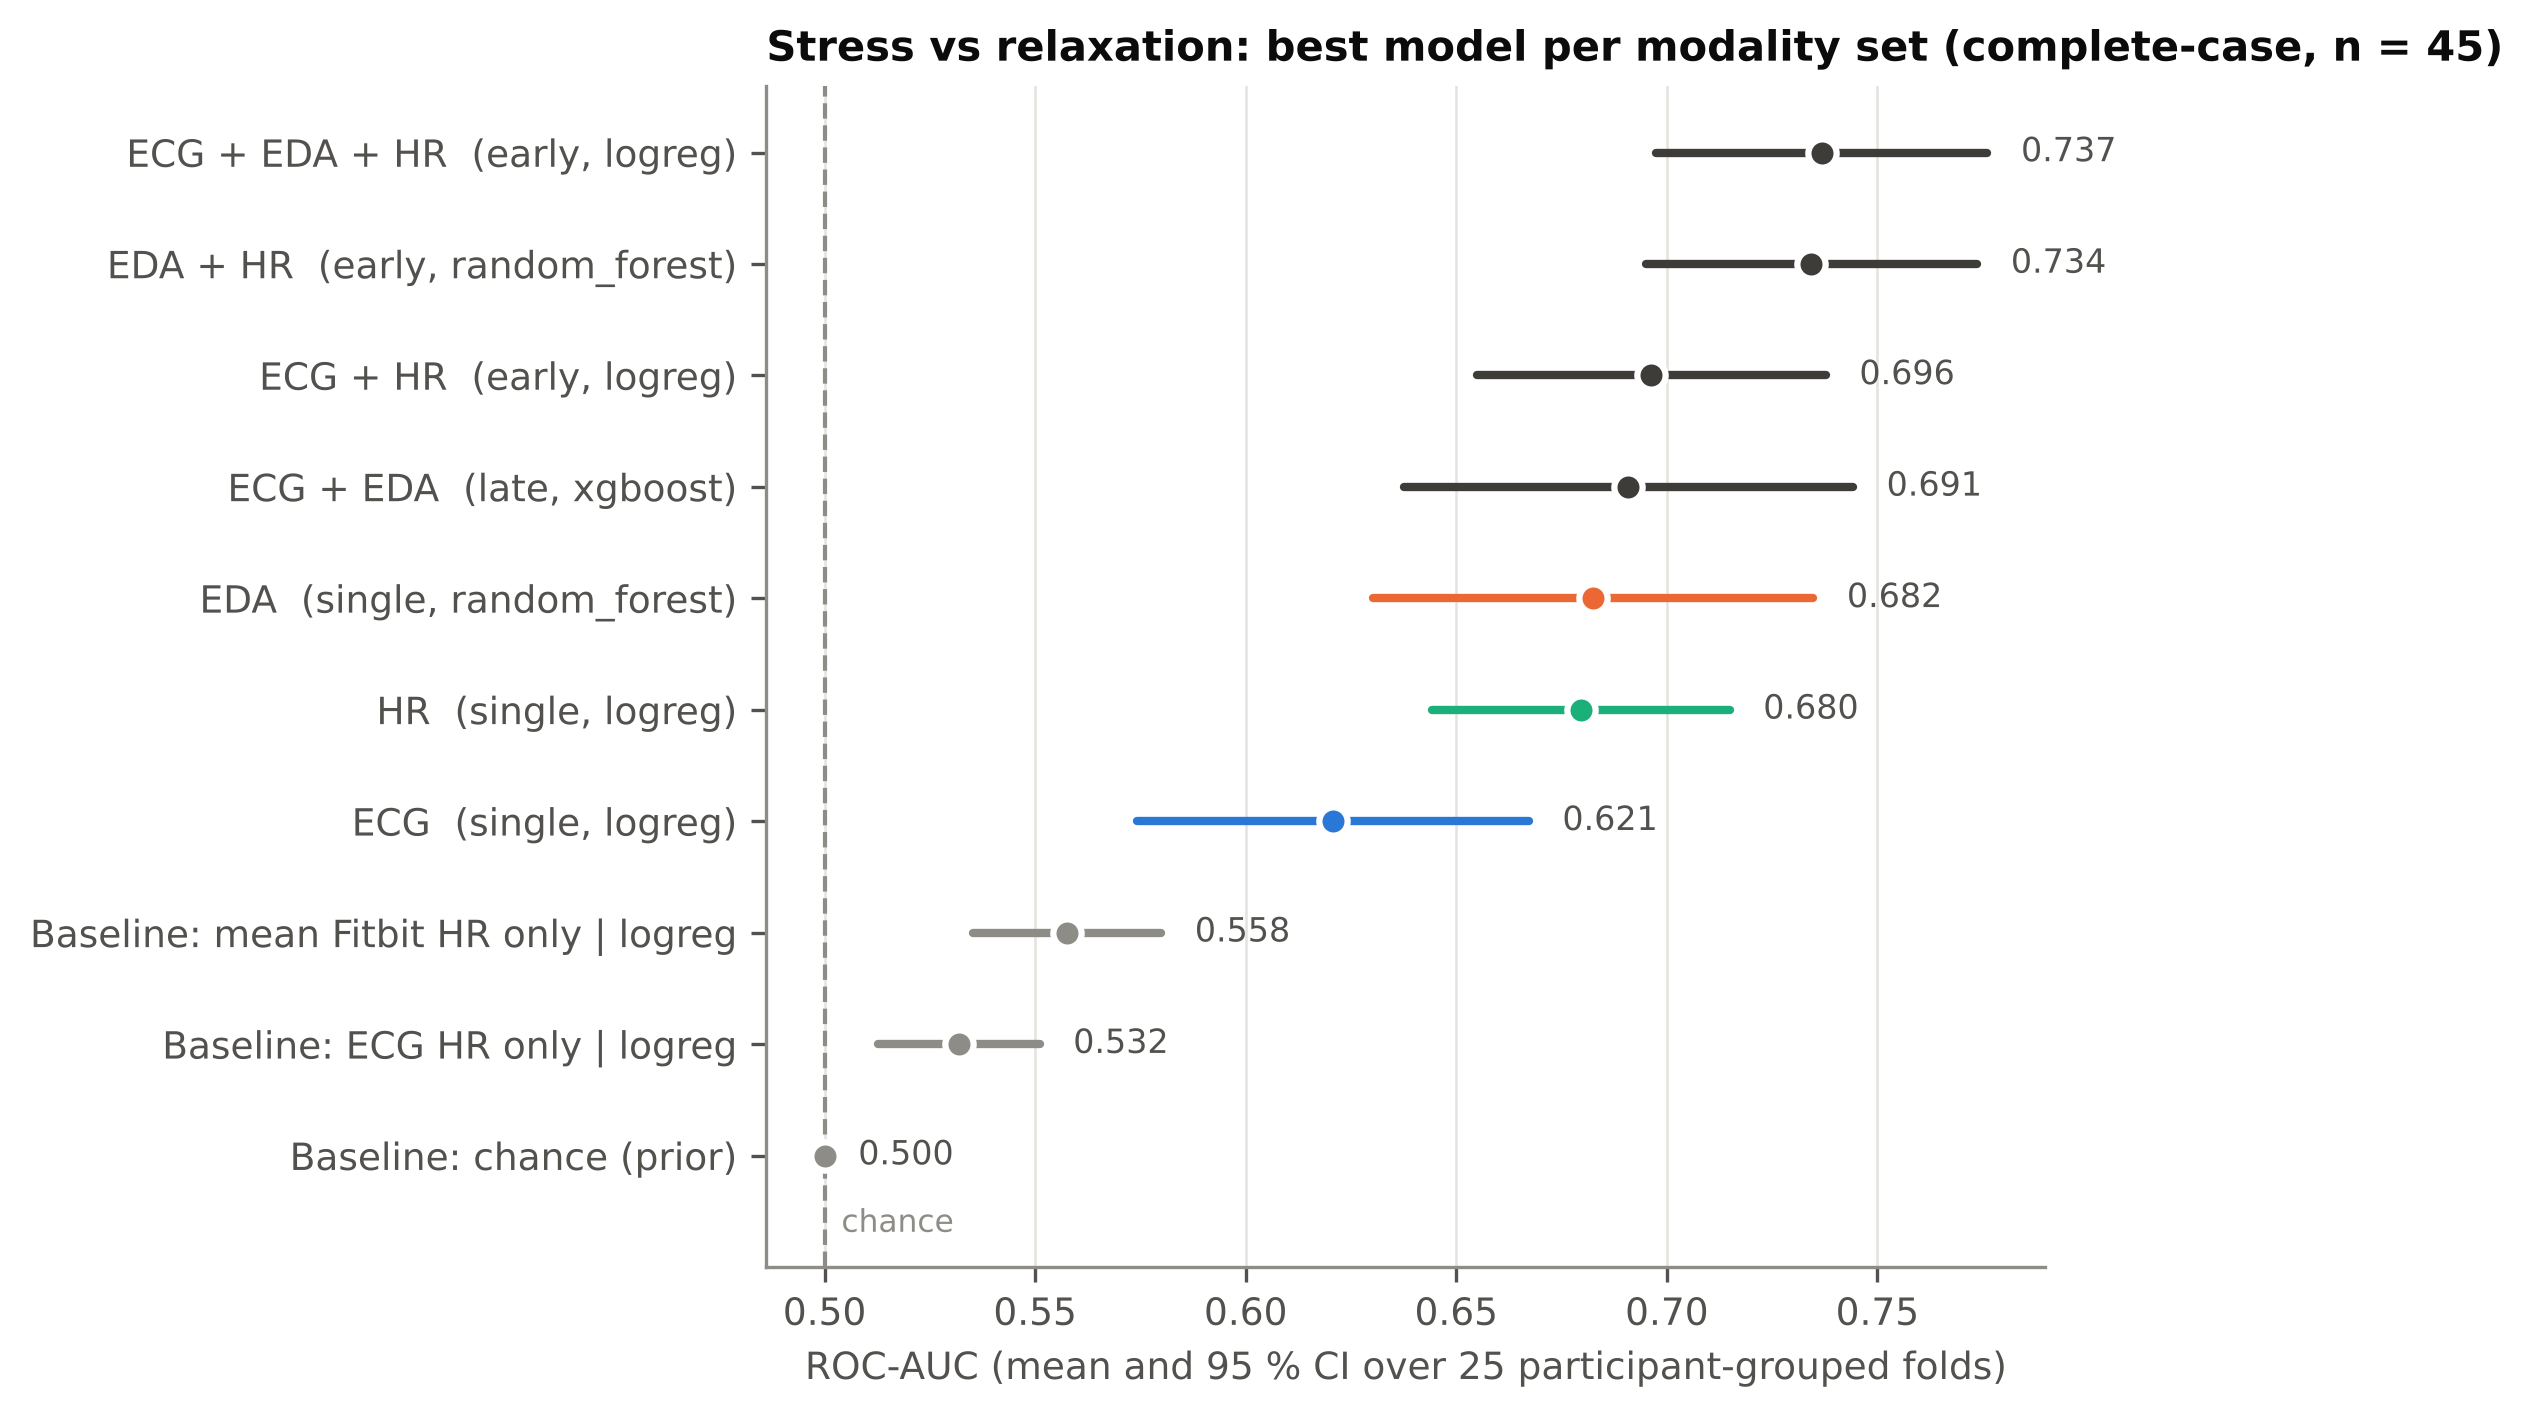

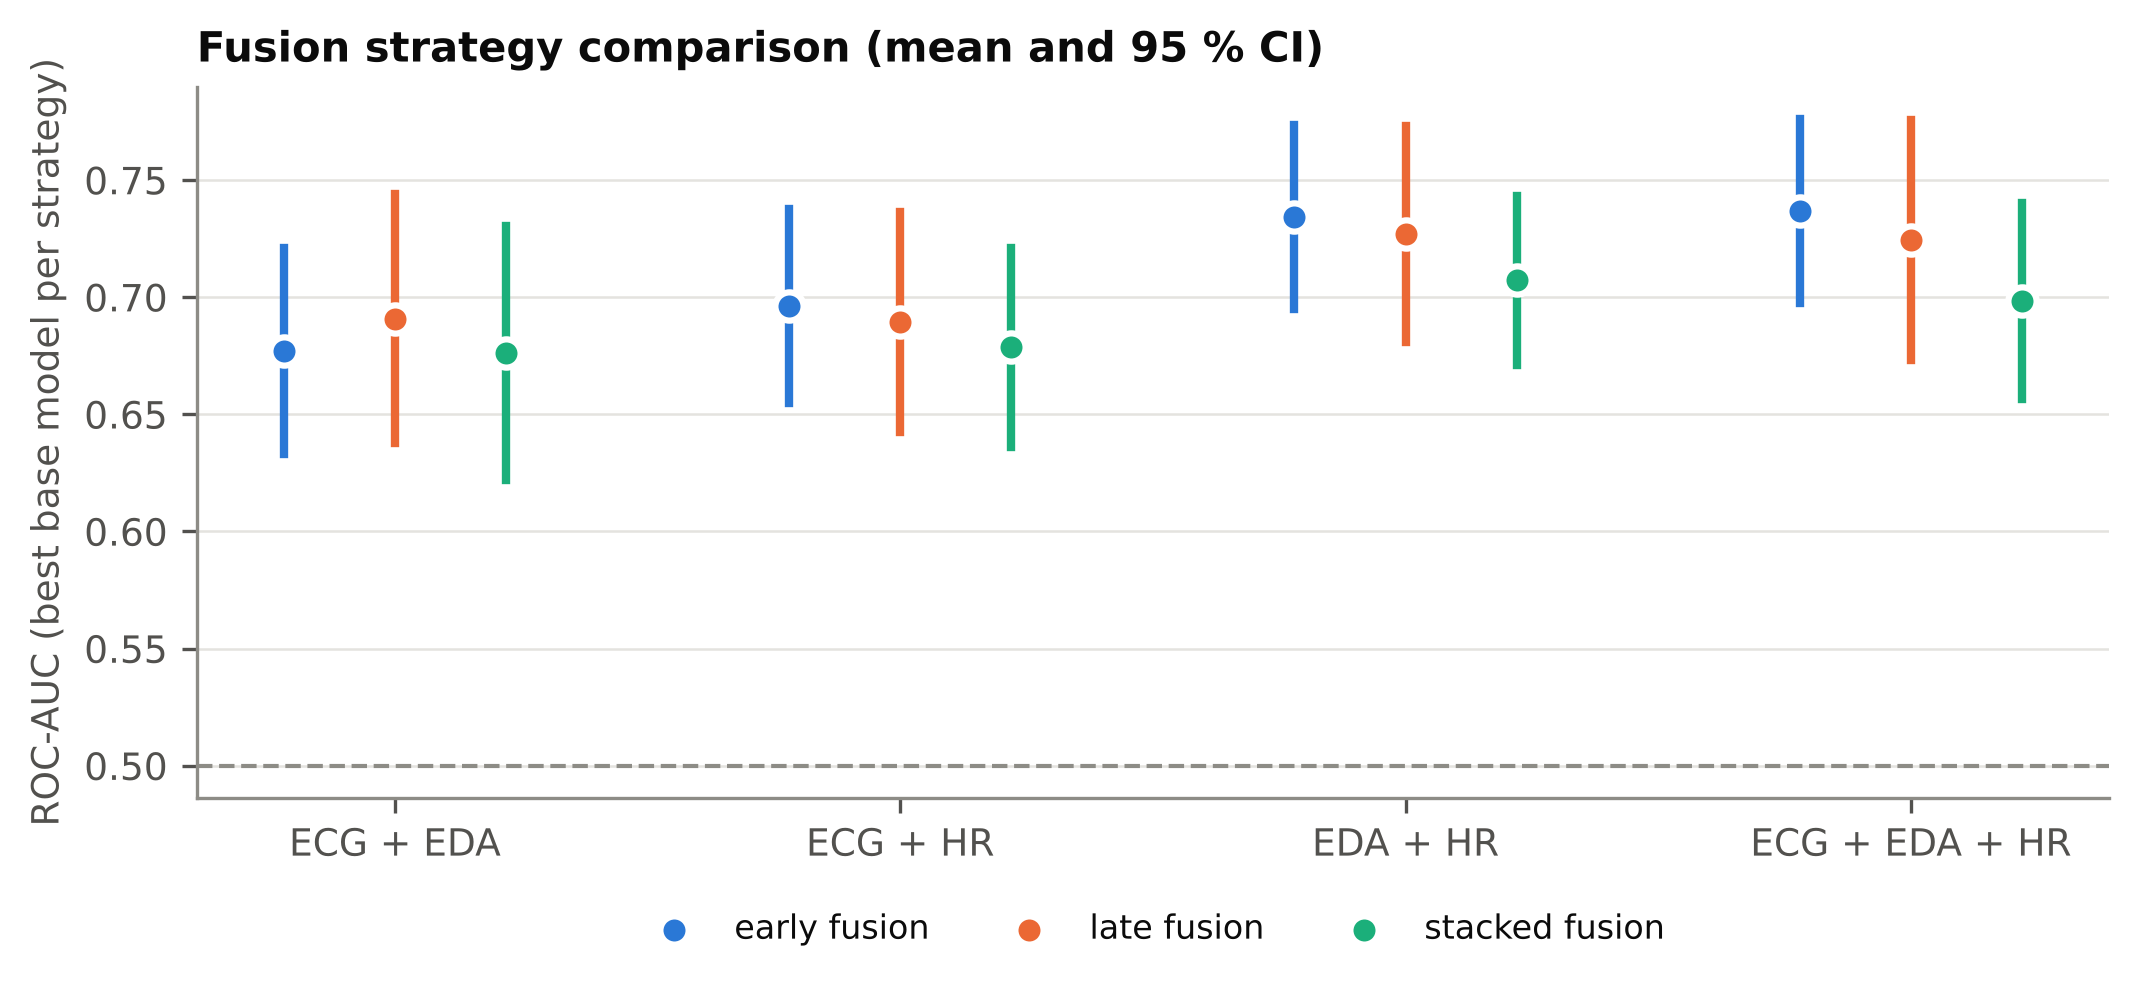

In [2]:
display(Image(F/'qol_modality_comparison.png', width=700)); display(Image(F/'qol_fusion_strategies.png', width=700))

## Statistical comparisons (Nadeau-Bengio corrected resampled t-test on fold AUCs)

In [3]:
pd.read_csv(M/'qol_model_comparisons.csv').round(4)

,model_a,model_b,metric,mean_diff,t,p_value
0,ECG+EDA+HR | early | logreg,EDA+HR | early | random_forest,roc_auc,0.0025,0.0429,0.9661
1,ECG+EDA+HR | early | logreg,ECG+HR | early | logreg,roc_auc,0.0405,0.8803,0.3874
2,ECG+EDA+HR | early | logreg,ECG+EDA | late | xgboost,roc_auc,0.0459,0.7588,0.4554
3,ECG+EDA+HR | early | logreg,EDA | single | random_forest,roc_auc,0.0543,0.7360,0.4689
4,ECG+EDA+HR | early | logreg,HR | single | logreg,roc_auc,0.0573,1.0305,0.3130
5,ECG+EDA+HR | early | logreg,ECG | single | logreg,roc_auc,0.1160,2.2139,0.0366
6,ECG+EDA+HR | early | logreg,Baseline | chance (prior),roc_auc,0.2368,4.3848,0.0002
7,ECG+EDA+HR | early | logreg,Baseline | mean Fitbit HR only | logreg,roc_auc,0.1793,4.0760,0.0004
8,ECG+EDA | late | logreg,ECG+EDA | early | logreg,roc_auc,-0.0049,-0.1245,0.9019
9,ECG+EDA | late | xgboost,ECG+EDA | early | logreg,roc_auc,0.0138,0.2321,0.8184


## Learned stacking weights

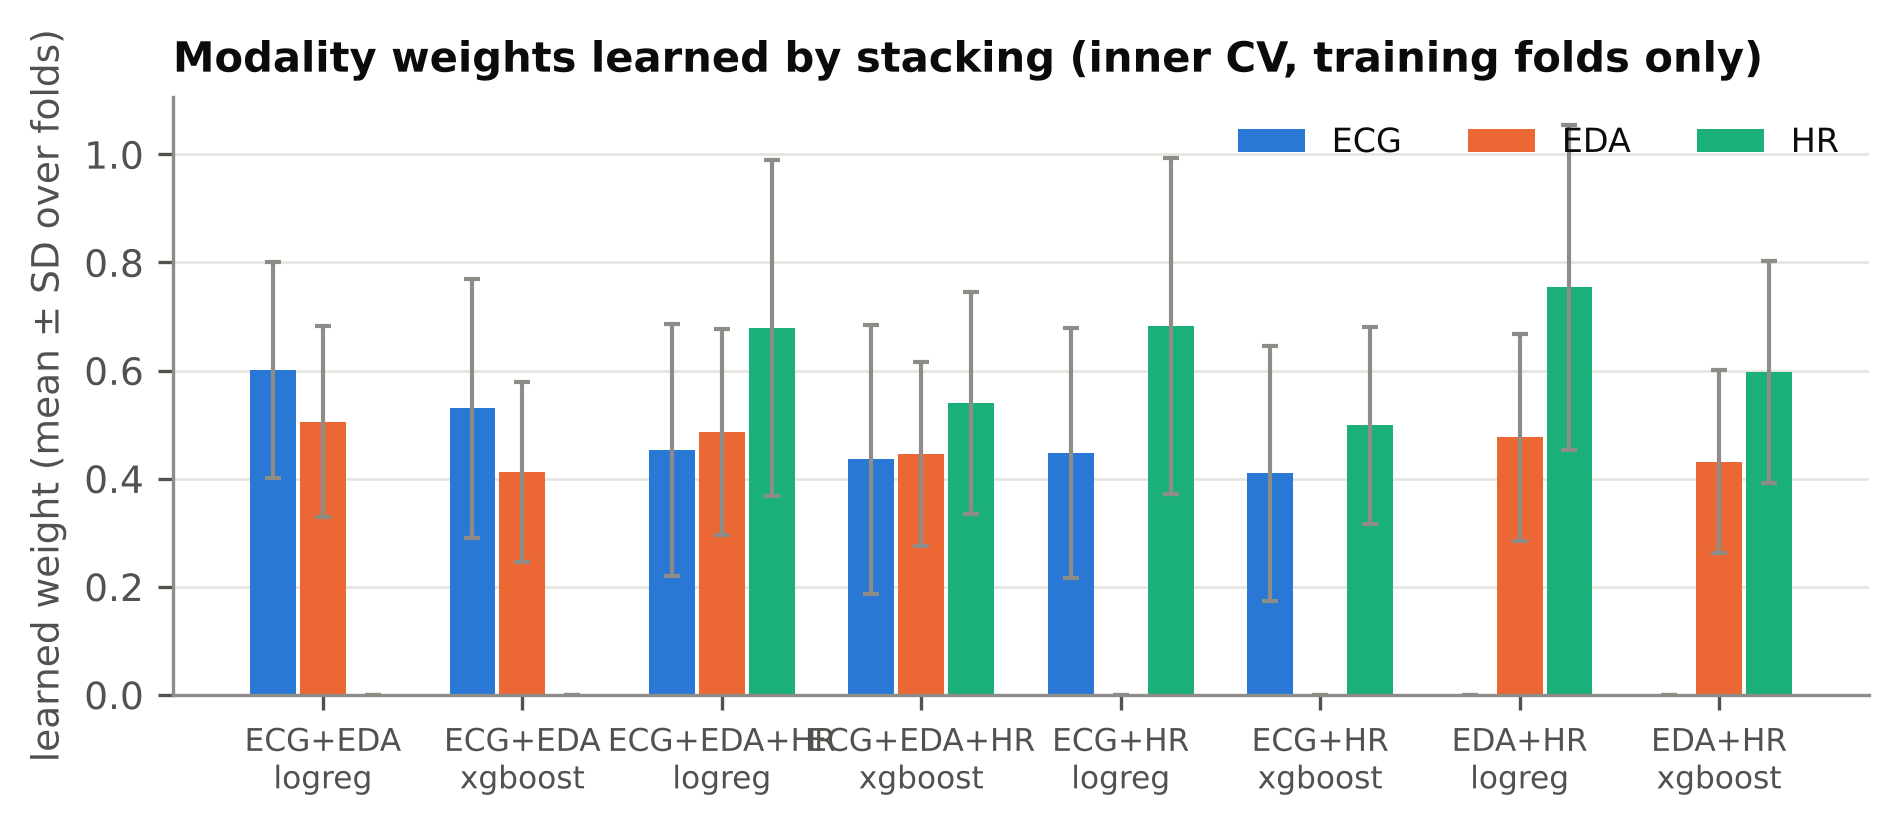

In [4]:
display(Image(F/'qol_stacking_weights.png', width=650))

## Permutation tests and sensitivity analyses

In [5]:
display(pd.read_csv(M/'qol_permutation_tests.csv').round(4)); pd.read_csv(M/'qol_sensitivity.csv').round(3)

,experiment,observed_auc_single_repeat,n_permutations,null_mean,null_95th,p_value
0,ECG | single | logreg,0.6346,200,0.4986,0.6002,0.0149
1,EDA | single | logreg,0.6543,200,0.4928,0.6001,0.0050
2,EDA | single | random_forest,0.7111,50,0.4912,0.6052,0.0392
3,HR | single | logreg,0.6963,200,0.4988,0.6173,0.0050
4,ECG+EDA+HR | early | logreg,0.7407,200,0.4986,0.6025,0.0050


,analysis,experiment,n_participants,n_rows,roc_auc_mean,roc_auc_sd,balanced_accuracy_mean,pairwise_accuracy_mean
0,available_case_all_66,ECG+EDA+HR | early | logreg,66,132,0.685,0.083,0.624,0.742
1,available_case_all_66,ECG+EDA+HR | late | logreg,66,132,0.657,0.081,0.639,0.696
2,available_case_all_66,ECG+EDA+HR | stacked | logreg,66,132,0.666,0.079,0.623,0.654
3,complete_case_ecg_timestamp_consistent,ECG+EDA+HR | early | logreg,34,68,0.700,0.092,0.622,0.754
4,complete_case_ecg_timestamp_consistent,ECG+EDA+HR | late | logreg,34,68,0.696,0.116,0.643,0.736
5,complete_case_ecg_timestamp_consistent,ECG+EDA+HR | stacked | logreg,34,68,0.655,0.117,0.619,0.661


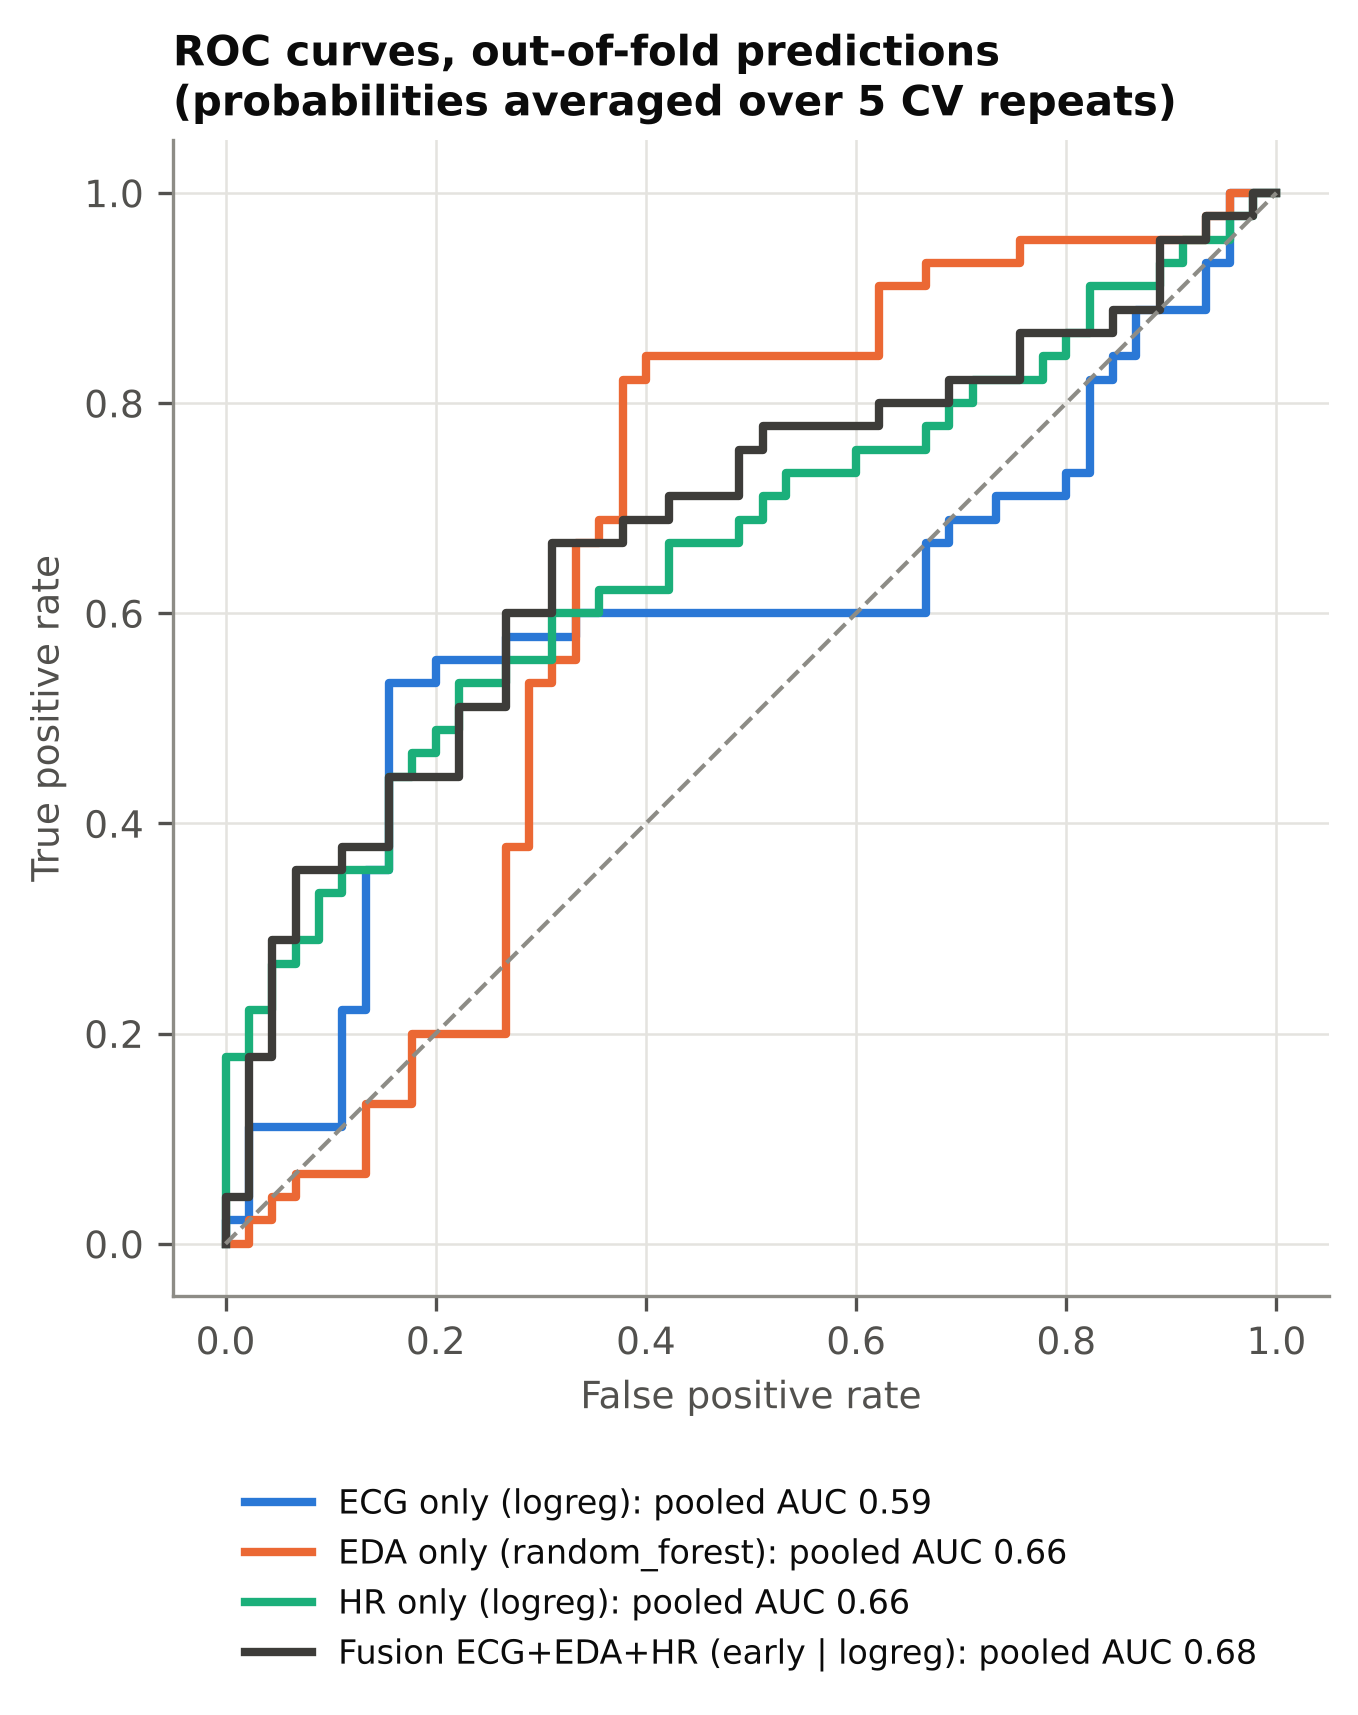

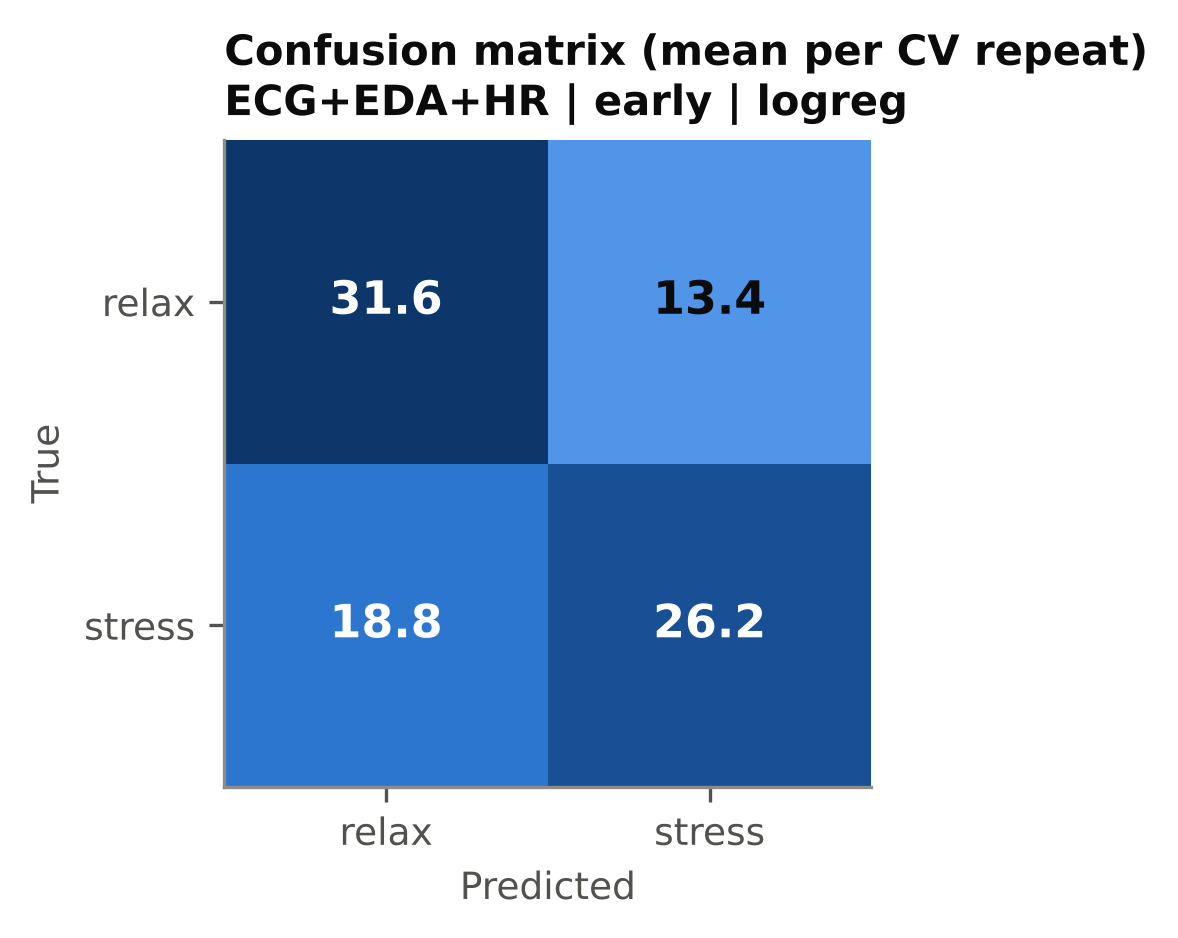

In [6]:
display(Image(F/'qol_roc_curves.png', width=420)); display(Image(F/'qol_confusion_matrix_best.png', width=330))